# SPY intraday momentum: baseline vs. partial gap

Backtest of the strategy from *Beat the Market: An Effective Intraday Momentum Strategy for SPY*
(Zarattini, Aziz, Barbon) and my modification, which uses only 50% of the overnight gap for the noise area.

- **Development:** 2019-10-25 to 2023-10-06 (the first 14 days are only used to warm up the indicators)
- **Test:** 2023-10-09 to 2026-10-06
- Costs: $0.0035/share commission (min $0.35/order) and $0.001/share slippage on every order

All the logic is in `backtest.py`. This notebook only shows the results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import backtest as bt
from zoneinfo import ZoneInfo
import matplotlib.dates as mdates

bars, checkpoints, days, daily, trades, performance = bt.run_all()
print(f"{len(bars):,} regular-session minute bars, {len(days)} trading days, {len(trades):,} trades")

683,425 regular-session minute bars, 1759 trading days, 6,472 trades


## 1. Results

In [2]:
table = performance[performance.period != "Full"].set_index(["period", "strategy"])
cols = ["total_return", "annual_return", "annual_vol", "sharpe", "max_drawdown", "trades"]
table[cols].style.format({c: "{:.1%}" for c in cols[:3] + ["max_drawdown"]} | {"sharpe": "{:.2f}"})

,,total_return,annual_return,annual_vol,sharpe,max_drawdown,trades
period,strategy,,,,,,
Development,SPY Buy & Hold,50.8%,11.0%,22.3%,0.58,33.6%,0
Test,SPY Buy & Hold,81.8%,22.2%,14.0%,1.50,17.7%,1
Development,Baseline (fixed 1x),45.3%,9.9%,7.7%,1.27,9.8%,818
Test,Baseline (fixed 1x),2.3%,0.8%,5.5%,0.17,10.4%,668
Development,Baseline (vol target),163.4%,27.8%,14.8%,1.73,10.8%,817
Test,Baseline (vol target),6.1%,2.0%,14.1%,0.21,25.9%,668
Development,Partial gap (fixed 1x),27.7%,6.4%,8.6%,0.76,17.3%,978
Test,Partial gap (fixed 1x),1.2%,0.4%,7.4%,0.09,10.6%,773
Development,Partial gap (vol target),142.1%,25.1%,15.9%,1.49,12.4%,977


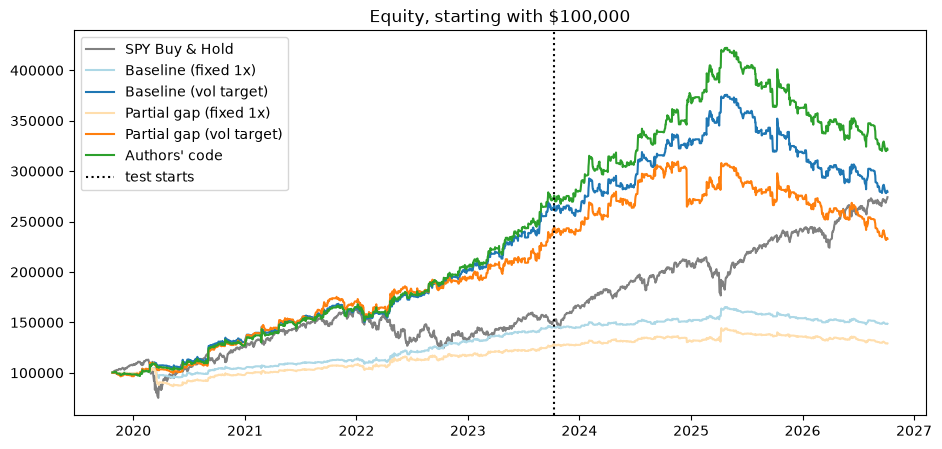

In [3]:
colors = {"SPY Buy & Hold": "gray", "Baseline (fixed 1x)": "lightblue", "Baseline (vol target)": "tab:blue",
          "Partial gap (fixed 1x)": "navajowhite", "Partial gap (vol target)": "tab:orange", "Authors' code": "tab:green"}

fig, ax = plt.subplots(figsize=(11, 5))
for name, d in daily.groupby("strategy", sort=False):
    ax.plot(pd.to_datetime(d.date), d.equity, label=name, color=colors[name])
ax.axvline(pd.Timestamp(bt.TEST_START), color="black", linestyle=":", label="test starts")
ax.set_title("Equity, starting with $100,000")
ax.legend()
plt.savefig("results/charts/01_equity.png", dpi=150, bbox_inches="tight")
plt.show()

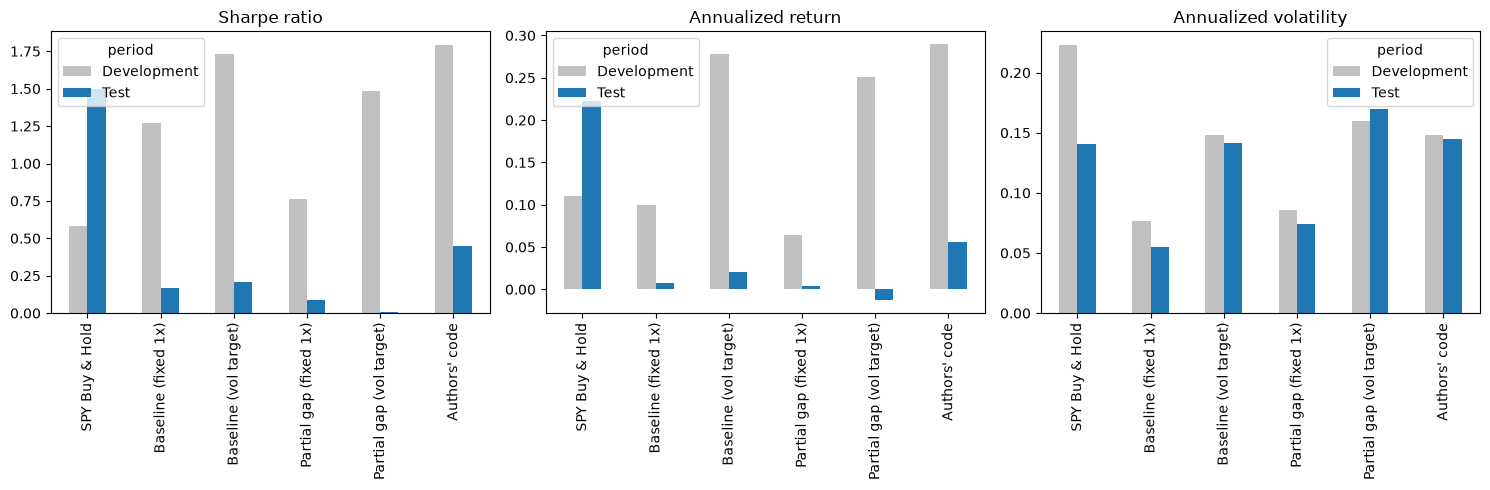

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
names = list(colors)
for ax, metric, title in zip(axes, ["sharpe", "annual_return", "annual_vol"],
                             ["Sharpe ratio", "Annualized return", "Annualized volatility"]):
    t = performance.pivot(index="strategy", columns="period", values=metric).loc[names]
    t[["Development", "Test"]].plot.bar(ax=ax, color=["silver", "tab:blue"])
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("results/charts/02_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. What does the partial gap change?

Compare the signals of the two strategies at every 30-minute checkpoint,
and check on which days the partial gap enters earlier.

In [ ]:
sig = pd.DataFrame({name: bt.get_signals(checkpoints, w) for name, w in bt.STRATEGIES.items()})
sig["date"] = checkpoints.date
sig = sig[sig.date >= days.index[bt.LOOKBACK]]

rows = []
for period, part in [("Development", sig[sig.date < bt.TEST_START]), ("Test", sig[sig.date >= bt.TEST_START])]:
    t = trades[trades.date.isin(part.date) & trades.strategy.str.contains("vol target")]
    first_entry = t.groupby(["date", "strategy"]).entry_time.min().unstack().dropna()
    rows.append({"period": period, "checkpoints": len(part),
                 "different signals": (part.Baseline != part["Partial gap"]).sum(),
                 "days both trade": len(first_entry),
                 "partial gap enters earlier": (first_entry["Partial gap (vol target)"] < first_entry["Baseline (vol target)"]).sum(),
                 "trades baseline": (t.strategy == "Baseline (vol target)").sum(),
                 "trades partial gap": (t.strategy == "Partial gap (vol target)").sum()})
pd.DataFrame(rows).set_index("period")

,checkpoints,different signals,days both trade,partial gap enters earlier,trades baseline,trades partial gap
period,,,,,,
Development,11366,455,575,76,817,977
Test,8480,358,455,60,668,773


Example: the day with the biggest overnight gap (in development) where the two strategies disagree.
Dashed lines are the noise area bands, triangles are entries.

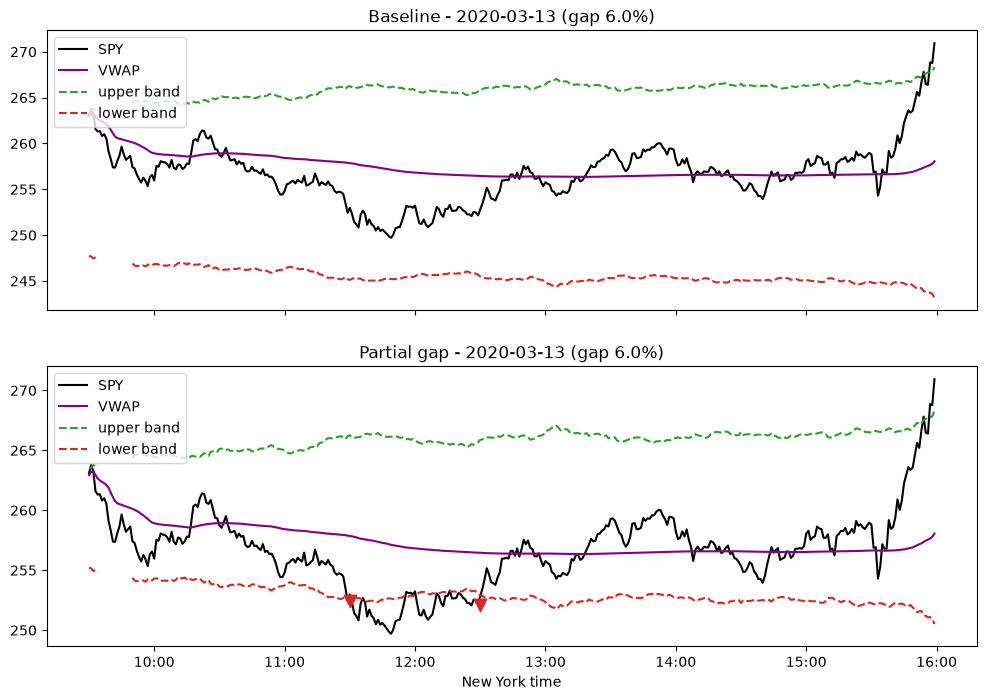

In [7]:
changed_days = sig[sig.Baseline != sig["Partial gap"]].date.unique()
gap = (days.open / days.prev_close - 1).loc[changed_days]
example = gap[gap.index < bt.TEST_START].abs().idxmax()
day = bars[bars.date == example]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, (name, weight) in zip(axes, bt.STRATEGIES.items()):
    upper, lower = bt.noise_area(day.day_open, day.prev_close, day.sigma, weight)
    ax.plot(day.index, day.close, color="black", label="SPY")
    ax.plot(day.index, day.vwap, color="purple", label="VWAP")
    ax.plot(day.index, upper, "--", color="tab:green", label="upper band")
    ax.plot(day.index, lower, "--", color="tab:red", label="lower band")
    t = trades[(trades.date == example) & (trades.strategy == name + " (vol target)")]
    for _, tr in t.iterrows():
        ax.scatter(tr.entry_time, day.open.get(tr.entry_time, np.nan),
        marker="^" if tr.side == "long" else "v", s=80,
        color="tab:green" if tr.side == "long" else "tab:red", zorder=5)
    ax.set_title(f"{name} - {example} (gap {gap[example]:.1%})")
    ax.legend(loc="upper left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=ZoneInfo(bt.NY)))
axes[-1].set_xlabel("New York time")    
plt.savefig("results/charts/03_example_day.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Conclusion

In the test period, the partial-gap modification did not improve the volatility-targeted result. SPY buy and hold performed better than either strategy version. This retrospective comparison does not establish a stable advantage for the modification.